Brayden Yow  
09/14/2026  
Lab 3 — Oscillator Simulation

In [13]:
import numpy as np
import matplotlib.pyplot as plt

Part A — The Simple Harmonic Oscillator

In [14]:
k = 1.0  # spring constnat 
m = 1.0  

# Initial conditions
x0 = 1.0  
v0 = 0.0  

# Natural angular frequency and period
omega0 = np.sqrt(k / m)    # rad/s
T = 2 * np.pi / omega0     # s

# Exact solution for release from rest at x0
def exact_x(t):
    return x0 * np.cos(omega0 * t)

def exact_v(t):
    return -x0 * omega0 * np.sin(omega0 * t)

# Report characteristic quantities
initial_energy = 0.5 * k * x0**2 + 0.5 * m * v0**2

print(f"Natural angular frequency: {omega0:.4f} rad/s")
print(f"Period: {T:.4f} s")
print(f"Initial mechanical energy: {initial_energy:.4f} J")

Natural angular frequency: 1.0000 rad/s
Period: 6.2832 s
Initial mechanical energy: 0.5000 J


In [15]:
def simulate_sho(method, dt, n_periods=10):
# inital conditions 
    t_max = n_periods * T
    t = 0.0
    x = x0
    v = v0

    # Store the initial state and energy
    energy = 0.5 * k * x**2 + 0.5 * m * v**2

    t_history = [t]
    x_history = [x]
    v_history = [v]
    E_history = [energy]

    while t < t_max:
        # Acceleration from the CURRENT position
        a = -(k / m) * x

        if method == 'euler':
            x_new = x + v * dt
            v_new = v + a * dt
            x = x_new
            v = v_new

        elif method == 'euler-cromer':
            # Update velocity first
            v = v + a * dt

            
            x = x + v * dt

        t = t + dt
        energy = 0.5 * k * x**2 + 0.5 * m * v**2

        # Store the updated results
        t_history.append(t)
        x_history.append(x)
        v_history.append(v)
        E_history.append(energy)

    return (
        np.array(t_history),
        np.array(x_history),
        np.array(v_history),
        np.array(E_history)
    )

In [16]:
#standard Euler
t_e, x_e, v_e, E_e = simulate_sho('euler', dt=0.05)

#Euler-Cromer
t_ec, x_ec, v_ec, E_ec = simulate_sho('euler-cromer',dt=0.05)

# Check the simulation duration and final energies
print(f"Requested duration: { 10 * T:.4f} s")
print(f"Last stored time: {t_e[-1]:.4f} s")
print(f"Initial energy: {E_e[0]:.4f} J")
print(f"Euler final energy: {E_e[-1]:.4f} J")
print(f"Euler-Cromer final energy: {E_ec[-1]:.4f} J")

Requested duration: 62.8319 s
Last stored time: 62.8500 s
Initial energy: 0.5000 J
Euler final energy: 11.5355 J
Euler-Cromer final energy: 0.4994 J


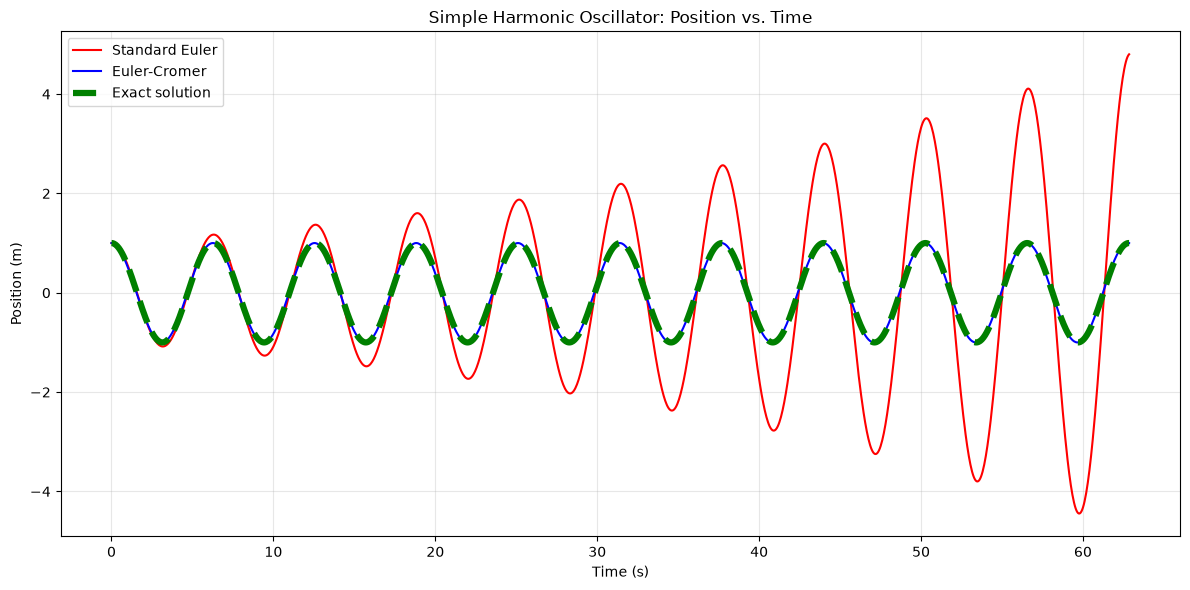

In [17]:
#The exact solution
x_exact = exact_x(t_e)

plt.figure(figsize=(12, 6))
plt.plot(t_e, x_e, 'r-',label='Standard Euler')
plt.plot(t_ec, x_ec,'b-', label='Euler-Cromer')
plt.plot(t_e, x_exact,'g--',label='Exact solution', linewidth=4.5)
plt.xlabel('Time (s)')
plt.ylabel('Position (m)')
plt.title('Simple Harmonic Oscillator: Position vs. Time')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

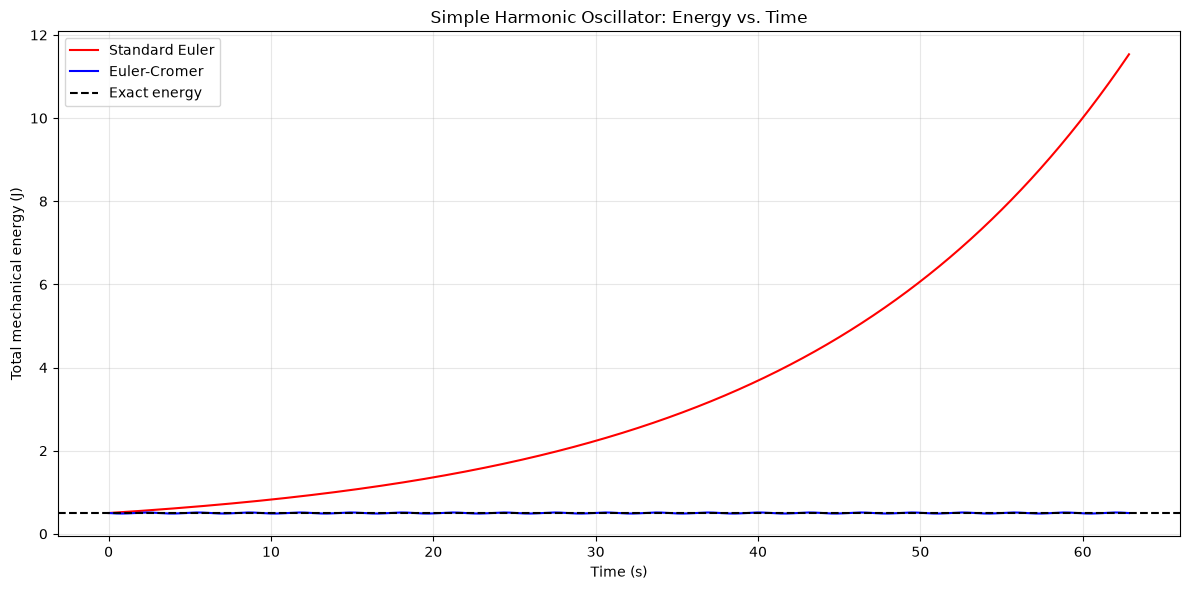

In [18]:
plt.figure(figsize=(12, 6))
plt.plot(t_e, E_e,'r-',label='Standard Euler')
plt.plot(t_ec, E_ec,'b-',label='Euler-Cromer')
plt.axhline(y=initial_energy,color='black',linestyle='--',label='Exact energy',linewidth=1.5)
plt.xlabel('Time (s)')
plt.ylabel('Total mechanical energy (J)')
plt.title('Simple Harmonic Oscillator: Energy vs. Time')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

What happens to the Euler solution's amplitude over 10 periods? What happens to its energy? Does Euler-Cromer show the same problem?

With every period of occultation, the Euler solution adds additional amplitude into the system. This also causes the total energy to increase at what seems to be an exponential rate. To view a more evident showing of the effects I set the period up to 100 and the pattern didn’t chang, it only grew. Euler-Cromer has no such problems even when expanded out to 100 occultations.

Part B — Phase Space & Damped Oscillations

B.1 — Phase-space portraits

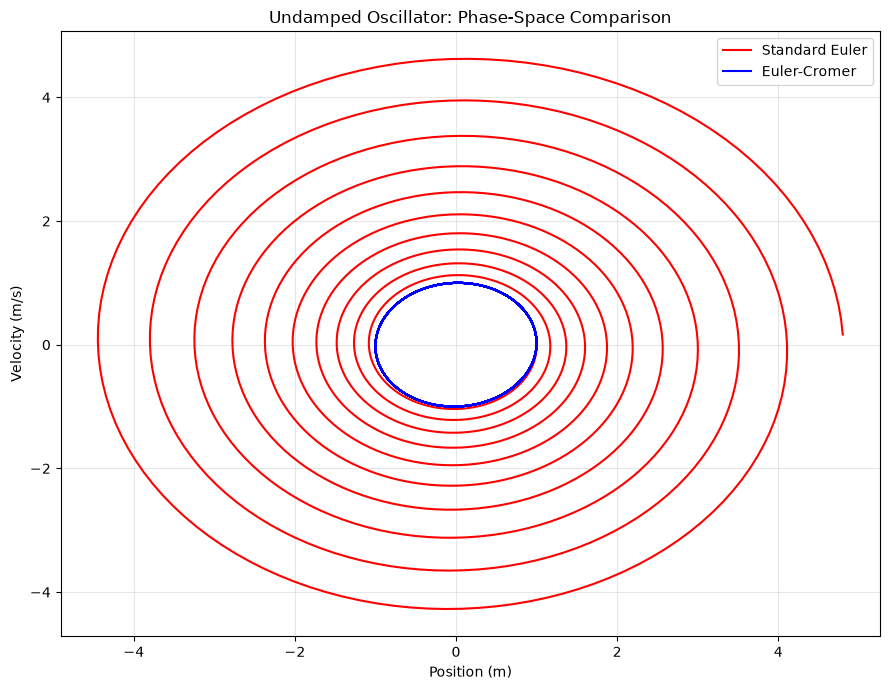

In [19]:
plt.figure(figsize=(9, 7))

#standard Euler
plt.plot(x_e, v_e,'r-', label='Standard Euler')

#Euler-Cromer
plt.plot(x_ec, v_ec,'b-',label='Euler-Cromer')

# Both simulations start at the same position and velocity
#+plt.plot(x0, v0,marker='o',color='black',linestyle='None',label='Initial state',markersize=6)

plt.xlabel('Position (m)')
plt.ylabel('Velocity (m/s)')
plt.title('Undamped Oscillator: Phase-Space Comparison')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

What does the Euler curve do? What does the Euler-Cromer curve do? Connect the shape to what you saw in the energy plot.

The Euler curve seems to be creating a spiral away from the starting point while the Euler-Cromer seems to be following the same path. This fallows the two plots made in part A where the Euler-Cromer followed the exact path while the standard Euler didn’t.

B.2 — Add damping

In [20]:
def simulate_damped_sho(b, dt=0.01, t_max=45.0):
    # Initial conditins
    t = 0.0
    x = x0
    v = v0

    # Initial energy
    energy = 0.5 * k * x**2 + 0.5 * m * v**2

    # array
    t_history = [t]
    x_history = [x]
    v_history = [v]
    E_history = [energy]

    while t < t_max:
        # Spring and damping acceleration from the current state
        a = -(k / m) * x - (b / m) * v

        # Euler-Cromer
        v = v + a * dt
        x = x + v * dt
        t = t + dt

        #energy updated
        energy = 0.5 * k * x**2 + 0.5 * m * v**2

        t_history.append(t)
        x_history.append(x)
        v_history.append(v)
        E_history.append(energy)

    return (
        np.array(t_history),
        np.array(x_history),
        np.array(v_history),
        np.array(E_history)
    )

In [21]:
dt_damped = 0.01
duration_damped = 45.0

# Damping coefficients
b_under = 0.2
b_critical = 2.0
b_over = 4.0

# Underdamped
t_under, x_under, v_under, E_under = simulate_damped_sho(b=b_under,dt=dt_damped,t_max=duration_damped)

# Critically damped
t_critical, x_critical, v_critical, E_critical = simulate_damped_sho(b=b_critical, dt=dt_damped, t_max=duration_damped)

# Overdamped
t_over, x_over, v_over, E_over = simulate_damped_sho(b=b_over, dt=dt_damped, t_max=duration_damped)

#the damping ratios
zeta_under = b_under / (2 * np.sqrt(k * m))
zeta_critical = b_critical / (2 * np.sqrt(k * m))
zeta_over = b_over / (2 * np.sqrt(k * m))

print(f"Underdamped damping ratio: {zeta_under:.2f}")
print(f"Critical damping ratio: {zeta_critical:.2f}")
print(f"Overdamped damping ratio: {zeta_over:.2f}")

Underdamped damping ratio: 0.10
Critical damping ratio: 1.00
Overdamped damping ratio: 2.00


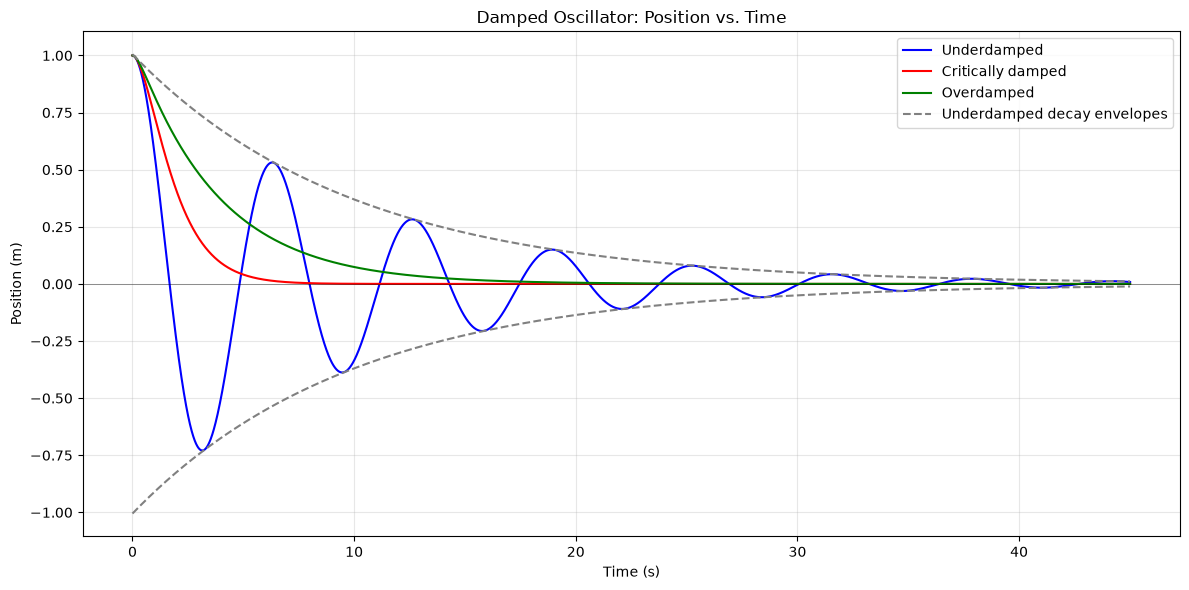

In [22]:
# Parameters for the underdamped theoretical envelope
beta_under = b_under / (2 * m)
omega1_under = np.sqrt(omega0**2 - beta_under**2)

# Envelope amplitude for release from rest at x0
A_envelope = np.sqrt(x0**2 + (beta_under * x0 / omega1_under)**2)

envelope = A_envelope * np.exp(-beta_under * t_under)

# Plot the solutions
plt.figure(figsize=(12, 6))

plt.plot(t_under, x_under,'b-',label='Underdamped')
plt.plot(t_critical, x_critical,'r-', label='Critically damped')
plt.plot(t_over, x_over,'g-', label='Overdamped')

# Upper and lower envelopes
plt.plot(t_under, envelope,color='gray',linestyle='--',label='Underdamped decay envelopes')
plt.plot(t_under, -envelope, color='gray', linestyle='--')
plt.axhline(y=0.0, color='black', linewidth=0.7, alpha=0.4)

plt.xlabel('Time (s)')
plt.ylabel('Position (m)')
plt.title('Damped Oscillator: Position vs. Time')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

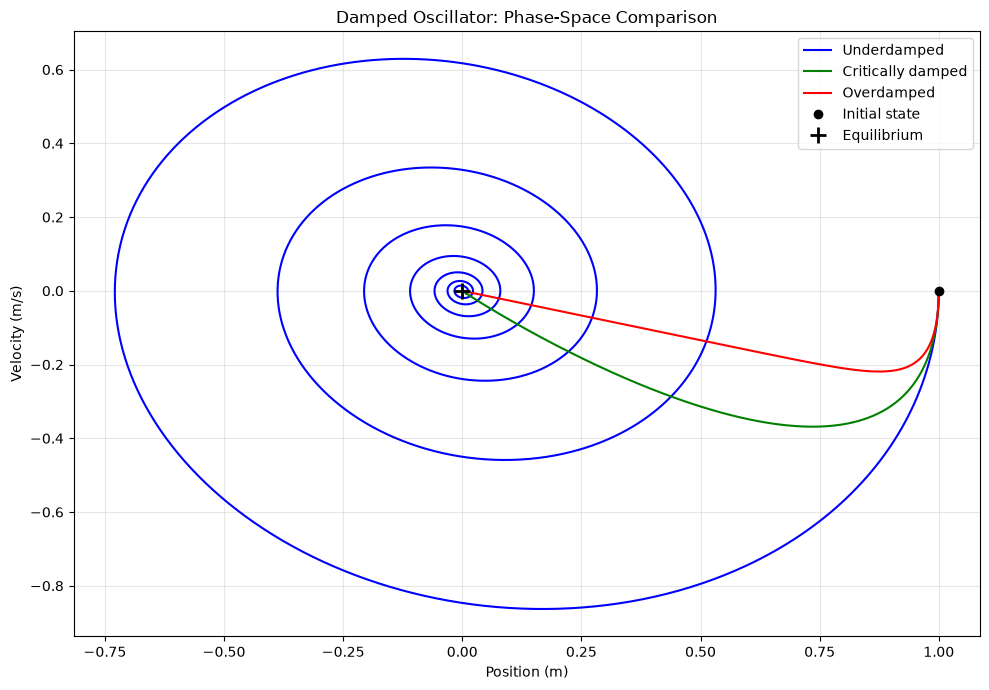

In [23]:
plt.figure(figsize=(10, 7))

plt.plot(x_under, v_under,'b-',label='Underdamped')

plt.plot(x_critical, v_critical,'g-', label='Critically damped')

plt.plot(x_over, v_over, 'r-',label='Overdamped')

# Shared initial state
plt.plot(x0, v0,marker='o',color='black',linestyle='None',label='Initial state')

# Equilibrium state
plt.plot(0.0, 0.0,marker='+', color='black',linestyle='None',markersize=12,markeredgewidth=2,label='Equilibrium')

plt.xlabel('Position (m)')
plt.ylabel('Velocity (m/s)')
plt.title('Damped Oscillator: Phase-Space Comparison')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Interpreting the phase-space plot: how does each regime spiral toward the origin differently?
The only plot that spiraled was the underdamped spring. This is because this is the only one of the three that maintained the oscillations. The critical damped system returned to the equilibrium state the fastest while the overdamped system took a longer path.


Part C — Driven Oscillations & Resonance

In [24]:
def simulate_driven_sho(omega_d, F0=1.0, b=0.2,dt=0.01, t_max=150.0):
    # Start at equilibrium and at rest
    t = 0.0
    x = 0.0
    v = 0.0

    t_history = [t]
    x_history = [x]
    v_history = [v]
    E_history = [0.0]

    while t < t_max:
        # Forces evaluated at the current state and time
        force_spring = -k * x
        force_damping = -b * v
        force_driving = F0 * np.cos(omega_d * t)

        # Newton's second law
        a = (force_spring + force_damping + force_driving) / m

        # Euler-Cromer update
        v = v + a * dt
        x = x + v * dt
        t = t + dt

        # Mechanical energy at the updated state
        energy = 0.5 * k * x**2 + 0.5 * m * v**2

        t_history.append(t)
        x_history.append(x)
        v_history.append(v)
        E_history.append(energy)

    return (
        np.array(t_history),
        np.array(x_history),
        np.array(v_history),
        np.array(E_history)
    )

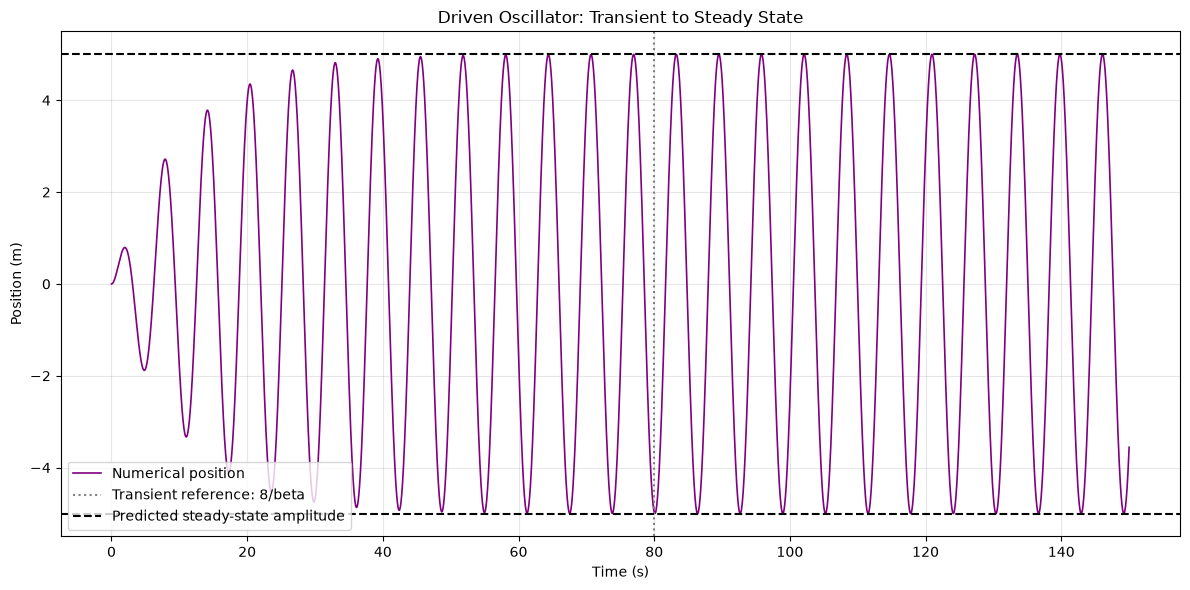

Driving angular frequency: 1.0000 rad/s
Transient reference time: 80.00 s
Predicted steady-state amplitude: 5.0000 m


In [25]:
# Driving and damping parameters
F0_driven = 1.0       # N
b_driven = 0.2        # kg/s
omega_d_test = omega0 # rad/s

# Run the simulation
t_driven, x_driven, v_driven, E_driven = simulate_driven_sho(
    omega_d=omega_d_test,
    F0=F0_driven,
    b=b_driven,
    dt=0.01,
    t_max=150.0
)

# Practical reference time for a small remaining transient
beta_driven = b_driven / (2 * m)
settling_time = 8 / beta_driven

# Analytical steady-state displacement amplitude (m)
A_steady = F0_driven / np.sqrt(
    (k - m * omega_d_test**2)**2
    + (b_driven * omega_d_test)**2
)

plt.figure(figsize=(12, 6))

plt.plot(
    t_driven, x_driven,
    color='purple',
    label='Numerical position',
    linewidth=1.2
)

plt.axvline(
    x=settling_time,
    color='gray',
    linestyle=':',
    label='Transient reference: 8/beta'
)

plt.axhline(
    y=A_steady,
    color='black',
    linestyle='--',
    label='Predicted steady-state amplitude'
)

plt.axhline(
    y=-A_steady,
    color='black',
    linestyle='--'
)

plt.xlabel('Time (s)')
plt.ylabel('Position (m)')
plt.title('Driven Oscillator: Transient to Steady State')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Driving angular frequency: {omega_d_test:.4f} rad/s")
print(f"Transient reference time: {settling_time:.2f} s")
print(f"Predicted steady-state amplitude: {A_steady:.4f} m")

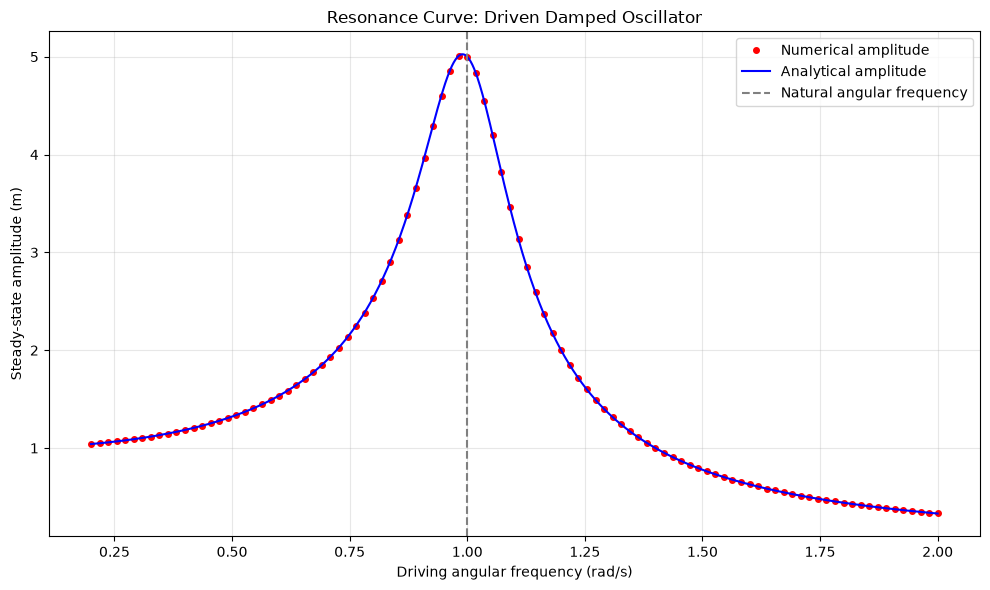

In [26]:
# Driving angular frequencies to test (rad/s)
omega_values = np.linspace(0.2, 2.0, 100)

# Store one measured amplitude per driving frequency
amplitudes = []

for omega_d in omega_values:
    t_run, x_run, v_run, E_run = simulate_driven_sho(
        omega_d=omega_d,
        F0=F0_driven,
        b=b_driven,
        dt=0.01,
        t_max=300.0
    )

    # Keep the final 20% of the position history
    tail_start = int(0.8 * len(x_run))
    x_tail = x_run[tail_start:]

    # Measure the steady-state amplitude
    amplitude = np.max(np.abs(x_tail))
    amplitudes.append(amplitude)

amplitudes = np.array(amplitudes)

# Analytical curve on a finer frequency grid
omega_reference = np.linspace(0.2, 2.0, 1000)

A_reference = F0_driven / np.sqrt(
    (k - m * omega_reference**2)**2
    + (b_driven * omega_reference)**2
)

plt.figure(figsize=(10, 6))

plt.plot(
    omega_values, amplitudes,
    color='red',
    marker='o',
    linestyle='None',
    markersize=4,
    label='Numerical amplitude'
)

plt.plot(
    omega_reference, A_reference,
    color='blue',
    linewidth=1.5,
    label='Analytical amplitude'
)

plt.axvline(
    x=omega0,
    color='gray',
    linestyle='--',
    label='Natural angular frequency'
)

plt.xlabel('Driving angular frequency (rad/s)')
plt.ylabel('Steady-state amplitude (m)')
plt.title('Resonance Curve: Driven Damped Oscillator')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Index of the largest measured amplitude
peak_index = np.argmax(amplitudes)

# Retrieve the frequency and amplitude at that index
omega_peak_numerical = omega_values[peak_index]
A_peak_numerical = amplitudes[peak_index]

# Analytical peak frequency
omega_peak_theory = np.sqrt(
    omega0**2 - 2 * beta_driven**2
)

# Spacing between tested frequencies
frequency_spacing = omega_values[1] - omega_values[0]

print(f"Natural angular frequency: {omega0:.6f} rad/s")
print(f"Numerical peak frequency: {omega_peak_numerical:.6f} rad/s")
print(f"Analytical peak frequency: {omega_peak_theory:.6f} rad/s")
print(f"Numerical peak amplitude: {A_peak_numerical:.6f} m")
print(f"Frequency-grid spacing: {frequency_spacing:.6f} rad/s")

Natural angular frequency: 1.000000 rad/s
Numerical peak frequency: 0.981818 rad/s
Analytical peak frequency: 0.989949 rad/s
Numerical peak amplitude: 5.004582 m
Frequency-grid spacing: 0.018182 rad/s


b = 0.1 kg/s: sampled peak at 1.000000 rad/s, amplitude = 10.000030 m
b = 0.2 kg/s: sampled peak at 0.981818 rad/s, amplitude = 5.004582 m
b = 0.5 kg/s: sampled peak at 0.945455 rad/s, amplitude = 2.061940 m


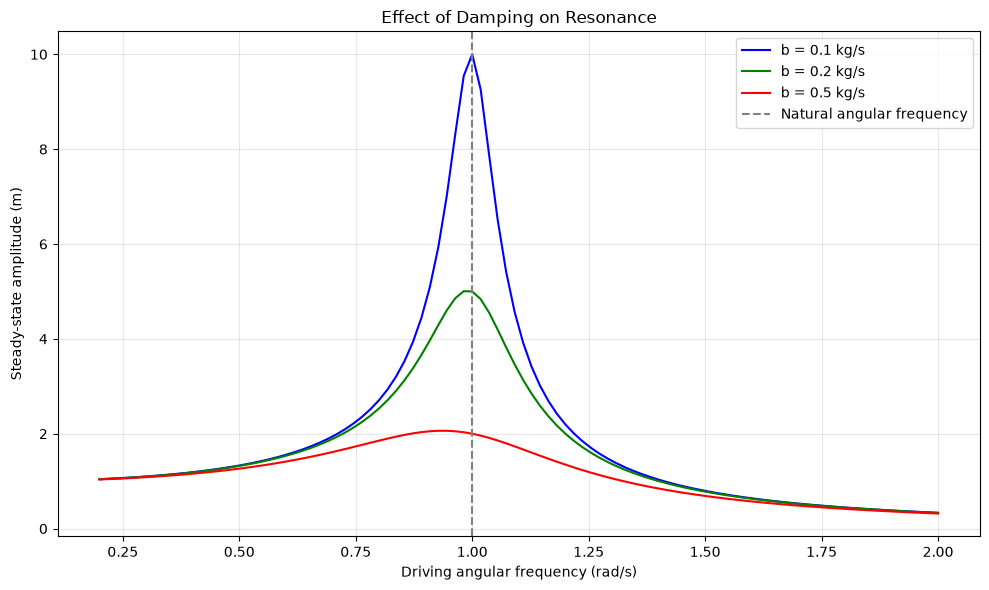

In [28]:
# Damping coefficients suggested in the assignment (kg/s)
damping_values = [0.1, 0.2, 0.5]
colors = ['blue', 'green', 'red']

plt.figure(figsize=(10, 6))

for b_value, color in zip(damping_values, colors):
    # Start a new amplitude list for this damping coefficient
    amplitudes_for_b = []

    for omega_d in omega_values:
        t_run, x_run, v_run, E_run = simulate_driven_sho(
            omega_d=omega_d,
            F0=F0_driven,
            b=b_value,
            dt=0.01,
            t_max=300.0
        )

        # Measure amplitude after the transient has decayed
        tail_start = int(0.8 * len(x_run))
        amplitude = np.max(np.abs(x_run[tail_start:]))
        amplitudes_for_b.append(amplitude)

    amplitudes_for_b = np.array(amplitudes_for_b)

    # Plot this damping coefficient's resonance curve
    plt.plot(
        omega_values, amplitudes_for_b,
        color=color,
        label=f'b = {b_value} kg/s',
        linewidth=1.5
    )

    # Report the largest sampled amplitude and its frequency
    peak_index_b = np.argmax(amplitudes_for_b)

    print(
        f"b = {b_value:.1f} kg/s: "
        f"sampled peak at {omega_values[peak_index_b]:.6f} rad/s, "
        f"amplitude = {amplitudes_for_b[peak_index_b]:.6f} m"
    )

plt.axvline(
    x=omega0,
    color='gray',
    linestyle='--',
    label='Natural angular frequency'
)

plt.xlabel('Driving angular frequency (rad/s)')
plt.ylabel('Steady-state amplitude (m)')
plt.title('Effect of Damping on Resonance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

why does the amplitude peak near ω₀? What would happen to the peak height if you reduced the damping?

The amplitude peaks near ω₀ because with the damping limiting the steady state amplitudes it peaks where the energy is most efficiently transferred. If the damping was reduced the peak would increase in height. This increase is from the more efficient use of energy without the damping it can act more directly on the system.